# Clasificación de familias de caracoles con Transfer Learning

Clasificación de imágenes de caracoles en **6 familias** usando **VGG16**


In [56]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print(f"GPUs detectadas: {len(gpus)}" if gpus else "Sin GPU: se entrenara en CPU")

GPUs detectadas: 1


## 1. Carga del dataset

In [57]:
from google.colab import drive
import shutil
import os
drive.mount('/content/drive')

ruta_drive = '/content/drive/MyDrive/CARACOLES.zip'
if os.path.exists(ruta_drive):
    shutil.copy(ruta_drive, 'CARACOLES.zip')
    print(f"Copiado {ruta_drive} → CARACOLES.zip ({os.path.getsize('CARACOLES.zip')/1e6:.1f} MB)")
else:
    print(f"No se encontró {ruta_drive}. Sube CARACOLES.zip manualmente o ajusta la ruta.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copiado /content/drive/MyDrive/CARACOLES.zip → CARACOLES.zip (404.5 MB)


In [58]:
import zipfile
import os

archivo_zip = 'CARACOLES.zip'
carpeta_destino = 'mis_imagenes'

if os.path.exists(archivo_zip):
    print(f"Descomprimiendo {archivo_zip} en '{carpeta_destino}'...")
    try:
        with zipfile.ZipFile(archivo_zip, 'r') as zip_ref:
            zip_ref.extractall(carpeta_destino)
        print("¡Descompresión completada con éxito!")
    except zipfile.BadZipFile:
        print("Error: El archivo ZIP está dañado o no es un formato válido.")
else:
    print(f"Error: No se encontró el archivo '{archivo_zip}' en el directorio actual.")

Descomprimiendo CARACOLES.zip en 'mis_imagenes'...
¡Descompresión completada con éxito!


In [59]:
import subprocess
import shutil
import os
if os.path.isdir('mis_imagenes/CARACOLES'):
    print("El dataset ya está extraído: no hace falta reparar el ZIP.")
elif shutil.which("zip") is None:
    print("El comando 'zip' no está disponible en este sistema; se omite la reparación.")
else:
    print("--- Intentando reparar el archivo ZIP con zip -FF ---")

    resultado_reparar = subprocess.run(["zip", "-FF", "CARACOLES.zip", "--out", "CARACOLES_reparado.zip"], capture_output=True, text=True)
    print(resultado_reparar.stdout)
    print(resultado_reparar.stderr)

    if os.path.exists("CARACOLES_reparado.zip"):
        print("\n--- Intentando descomprimir el archivo reparado ---")
        resultado_unzip = subprocess.run(["unzip", "-q", "CARACOLES_reparado.zip", "-d", "mis_imagenes"], capture_output=True, text=True)
        print(resultado_unzip.stdout)
        print(resultado_unzip.stderr)
        if os.path.exists("mis_imagenes"):
            print("¡Éxito! Se ha creado la carpeta 'mis_imagenes'.")
    else:
        print("No se pudo reparar el archivo automáticamente con zip.")

El dataset ya está extraído: no hace falta reparar el ZIP.


In [60]:
if os.path.isdir('mis_imagenes/CARACOLES'):
    print("El dataset ya está extraído: no hace falta 7-Zip.")
elif shutil.which("7z") is None:
    print("El comando '7z' no está instalado en este sistema; se omite este paso.")
else:
    print("--- Intentando descompresión alternativa con 7-Zip (7z) ---")

    resultado_7z = subprocess.run(["7z", "x", "CARACOLES.zip", "-omis_imagenes", "-y"], capture_output=True, text=True)
    print(resultado_7z.stdout[:1000] + "\n... [Salida recortada]" if len(resultado_7z.stdout) > 1000 else resultado_7z.stdout)
    print(resultado_7z.stderr)

El dataset ya está extraído: no hace falta 7-Zip.


In [61]:
clases = sorted(os.listdir('mis_imagenes/CARACOLES'))
print(f"{len(clases)} clases encontradas: {clases}")

6 clases encontradas: ['Cerithiidae', 'Embrionic_shell', 'Eulimidae', 'Litiopidae', 'Neritidae', 'Risooinidae']


In [62]:
directorio_datos = 'mis_imagenes/CARACOLES'

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

### Separación del dataset: 60% entrenamiento / 20% validación / 20% prueba

`image_dataset_from_directory` solo permite 2 subconjuntos y **no estratifica** (corte aleatorio de archivos). Con clases desbalanceadas se hace un split **estratificado**. Garantiza la misma proporción de cada familia en los tres conjuntos.

- **Validación**: Durante el entrenamiento.
- **Prueba**: Queda intacta hasta el final.

In [63]:
from sklearn.model_selection import train_test_split

class_names = sorted(d for d in os.listdir(directorio_datos)
                     if os.path.isdir(os.path.join(directorio_datos, d)))
num_classes = len(class_names)
print(f"Clases de caracoles encontradas ({num_classes}): {class_names}")

rutas, etiquetas = [], []
for i, clase in enumerate(class_names):
    archivos = os.listdir(os.path.join(directorio_datos, clase))
    rutas += [os.path.join(directorio_datos, clase, f) for f in archivos]
    etiquetas += [i] * len(archivos)
etiquetas = np.array(etiquetas)

# 60% train / 40% temporal, y el temporal se parte en 20% validación + 20% prueba
rutas_train, rutas_temp, y_train, y_temp = train_test_split(
    rutas, etiquetas, test_size=0.4, stratify=etiquetas, random_state=123)
rutas_val, rutas_test, y_val, y_test = train_test_split(
    rutas_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=123)

print(f"Entrenamiento: {len(rutas_train)} imágenes")
print(f"Validación:    {len(rutas_val)} imágenes")
print(f"Prueba:        {len(rutas_test)} imágenes")

Clases de caracoles encontradas (6): ['Cerithiidae', 'Embrionic_shell', 'Eulimidae', 'Litiopidae', 'Neritidae', 'Risooinidae']
Entrenamiento: 1778 imágenes
Validación:    593 imágenes
Prueba:        593 imágenes


### Construcción de los `tf.data.Dataset`

Se construye un `tf.data.Dataset` por subconjunto: lectura del archivo, decodificación a 3 canales, resize a `IMG_SIZE`, *shuffle* solo en entrenamiento, y `batch` + `prefetch` para eficiencia.

In [64]:
AUTOTUNE = tf.data.AUTOTUNE

def cargar_dataset(rutas, etiquetas, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))

    def _cargar(ruta, y):
        img = tf.io.read_file(ruta)
        img = tf.io.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, IMG_SIZE)
        return tf.cast(img, tf.uint8), y

    ds = ds.map(_cargar, num_parallel_calls=AUTOTUNE)
    if entrenamiento:
        ds = ds.shuffle(len(rutas), seed=123, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_dataset = cargar_dataset(rutas_train, y_train, entrenamiento=True)
validation_dataset = cargar_dataset(rutas_val, y_val)
test_dataset = cargar_dataset(rutas_test, y_test)

conteos_clases = {clase: len(os.listdir(os.path.join(directorio_datos, clase)))
                  for clase in class_names}
for clase, n in conteos_clases.items():
    print(f"  {clase}: {n} imágenes")

  Cerithiidae: 687 imágenes
  Embrionic_shell: 466 imágenes
  Eulimidae: 388 imágenes
  Litiopidae: 561 imágenes
  Neritidae: 704 imágenes
  Risooinidae: 158 imágenes


### Distribución de imágenes por clase

La clase minoritaria es **Risooinidae**: tiene ~4,5 veces menos imágenes que la mayoritaria (Neritidae), así que el dataset está desbalanceado.

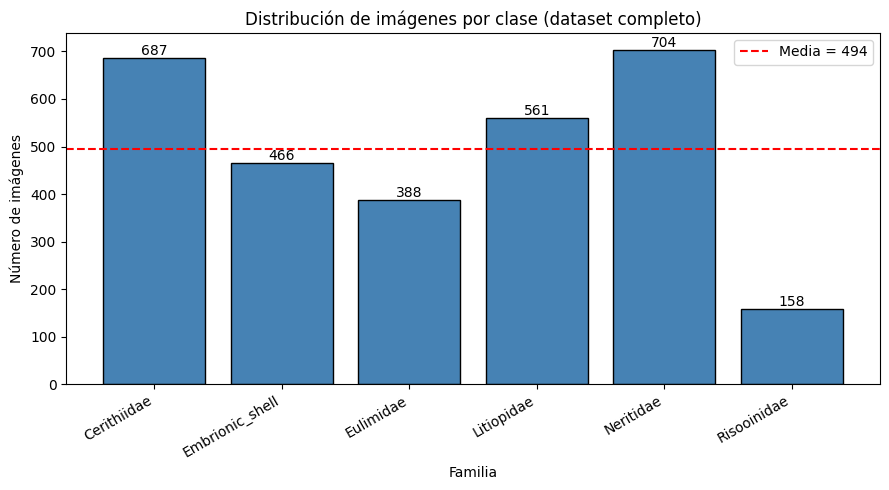

In [65]:
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(conteos_clases.keys(), conteos_clases.values(),
                color='steelblue', edgecolor='black')
media = sum(conteos_clases.values()) / len(conteos_clases)
ax.axhline(media, color='red', linestyle='--', label=f'Media = {media:.0f}')
for barra, v in zip(barras, conteos_clases.values()):
    ax.text(barra.get_x() + barra.get_width() / 2, v, str(v),
            ha='center', va='bottom')
ax.set_title('Distribución de imágenes por clase (dataset completo)')
ax.set_xlabel('Familia')
ax.set_ylabel('Número de imágenes')
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig('distribucion_clases.png', dpi=150)
plt.show()

**Optimizar la carga de datos**

### Pesos de clase para compensar el desbalance

`class_weight` multiplica la pérdida de cada muestra según su clase, de modo que los errores en clases minoritarias penalizan más. Se calcula solo con las etiquetas de entrenamiento (después del split) para no usar información del conjunto de validación.

In [66]:
train_labels = np.concatenate([y.numpy() for _, y in train_dataset])
conteos_train = np.bincount(train_labels, minlength=num_classes)
class_weights = {
    i: len(train_labels) / (num_classes * int(n))
    for i, n in enumerate(conteos_train)
}

for i, nombre in enumerate(class_names):
    print(f"  {nombre}: {conteos_train[i]} imágenes en train → peso {class_weights[i]:.3f}")

  Cerithiidae: 412 imágenes en train → peso 0.719
  Embrionic_shell: 280 imágenes en train → peso 1.058
  Eulimidae: 233 imágenes en train → peso 1.272
  Litiopidae: 336 imágenes en train → peso 0.882
  Neritidae: 422 imágenes en train → peso 0.702
  Risooinidae: 95 imágenes en train → peso 3.119


## 2. Aumento de datos y modelo base

In [67]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomRotation(0.2),
  tf.keras.layers.RandomZoom(0.2),
  tf.keras.layers.RandomContrast(0.2),
])

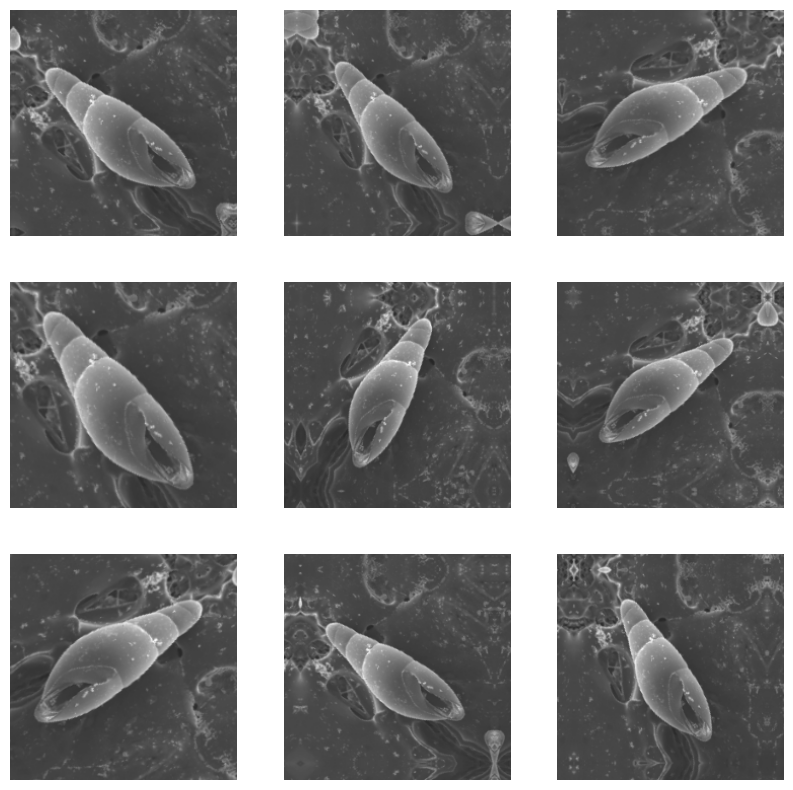

In [68]:
plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

In [69]:
IMG_SHAPE = IMG_SIZE + (3,)
base_learning_rate = 1e-3

preprocess_input = tf.keras.applications.vgg16.preprocess_input


def construir_modelo(usar_augmentation):
    base = tf.keras.applications.VGG16(input_shape=IMG_SHAPE,
                                       include_top=False,
                                       weights='imagenet')
    base.trainable = False

    inputs = tf.keras.Input(shape=IMG_SHAPE)
    x = inputs
    if usar_augmentation:
        x = data_augmentation(x)
    x = preprocess_input(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model, base


def crear_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                       restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                             patience=2, min_lr=1e-7),
    ]

FINETUNE_AT = 'block5_conv1'

def aplicar_fine_tuning(model, base):
    base.trainable = True
    corte = next(i for i, l in enumerate(base.layers) if l.name == FINETUNE_AT)
    for layer in base.layers[:corte]:
        layer.trainable = False
    print(f"Fine-tuning: {len(base.layers) - corte} capas descongeladas (desde '{FINETUNE_AT}')")

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate / 10),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

## 3. Extracción de características

### Modelo SIN data augmentation

In [70]:
initial_epochs = 10

print("--- Entrenando Modelo SIN Data Augmentation ---")
model_sin_aug, base_sin = construir_modelo(usar_augmentation=False)
history_sin = model_sin_aug.fit(train_dataset,
                              epochs=initial_epochs,
                              validation_data=validation_dataset,
                              class_weight=class_weights,
                              callbacks=crear_callbacks())

--- Entrenando Modelo SIN Data Augmentation ---
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 23s 274ms/step - accuracy: 0.5596 - loss: 2.2044 - val_accuracy: 0.9191 - val_loss: 0.2491 - learning_rate: 0.0010
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - accuracy: 0.8504 - loss: 0.5039 - val_accuracy: 0.9646 - val_loss: 0.1264 - learning_rate: 0.0010
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 224ms/step - accuracy: 0.9184 - loss: 0.2563 - val_accuracy: 0.9798 - val_loss: 0.0747 - learning_rate: 0.0010
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 225ms/step - accuracy: 0.9466 - loss: 0.1719 - val_accuracy: 0.9798 - val_loss: 0.0640 - learning_rate: 0.0010
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 218ms/step - accuracy: 0.9634 - loss: 0.1469 - val_accuracy: 0.9848 - val_loss: 0.0528 - learning_rate: 0.0010
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 251ms/step - accuracy: 0.9674 - loss: 0.1087 - val_accuracy: 0.9848 - val_loss: 0.0476 - learning_rate: 0.0010
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━

### Modelo CON data augmentation

In [71]:
print("\n--- Entrenando Modelo CON Data Augmentation ---")
model_con_aug, base_con = construir_modelo(usar_augmentation=True)
history_con = model_con_aug.fit(train_dataset,
                              epochs=initial_epochs,
                              validation_data=validation_dataset,
                              class_weight=class_weights,
                              callbacks=crear_callbacks())


--- Entrenando Modelo CON Data Augmentation ---
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 233ms/step - accuracy: 0.4668 - loss: 2.0059 - val_accuracy: 0.7960 - val_loss: 0.5384 - learning_rate: 0.0010
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 229ms/step - accuracy: 0.8189 - loss: 0.6208 - val_accuracy: 0.9191 - val_loss: 0.2258 - learning_rate: 0.0010
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 257ms/step - accuracy: 0.8931 - loss: 0.3557 - val_accuracy: 0.9629 - val_loss: 0.1288 - learning_rate: 0.0010
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 256ms/step - accuracy: 0.9297 - loss: 0.2371 - val_accuracy: 0.9629 - val_loss: 0.1154 - learning_rate: 0.0010
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 263ms/step - accuracy: 0.9241 - loss: 0.2250 - val_accuracy: 0.9663 - val_loss: 0.1035 - learning_rate: 0.0010
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 227ms/step - accuracy: 0.9454 - loss: 0.1853 - val_accuracy: 0.9781 - val_loss: 0.0760 - learning_rate: 0.0010
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━

## 4. Fine-tuning

Descongelamos el **último bloque convolucional (`block5`)** de VGG16 en **ambos** modelos y seguimos entrenando con una tasa de aprendizaje 10× menor. VGG16 solo tiene 19 capas agrupadas en 5 bloques, así que en lugar de descongelar un número fijo de capas se descongela el bloque final completo (las capas más especializadas). A diferencia de ResNet50, VGG16 no usa *batch normalization*, por lo que no hay que mantener esas capas en modo inferencia. Comparación SIN vs CON augmentation:

In [72]:
fine_tune_epochs = 10
ep_sin = len(history_sin.history['loss'])
aplicar_fine_tuning(model_sin_aug, base_sin)
print("--- Fine-tuning del modelo SIN Data Augmentation ---")
history_fine_sin = model_sin_aug.fit(train_dataset,
                                   epochs=ep_sin + fine_tune_epochs,
                                   initial_epoch=ep_sin,
                                   validation_data=validation_dataset,
                                   class_weight=class_weights,
                                   callbacks=crear_callbacks())

Fine-tuning: 4 capas descongeladas (desde 'block5_conv1')
--- Fine-tuning del modelo SIN Data Augmentation ---
Epoch 11/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 314ms/step - accuracy: 0.9623 - loss: 0.1769 - val_accuracy: 0.9916 - val_loss: 0.0440 - learning_rate: 1.0000e-04
Epoch 12/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 280ms/step - accuracy: 0.9921 - loss: 0.0257 - val_accuracy: 0.9865 - val_loss: 0.0540 - learning_rate: 1.0000e-04
Epoch 13/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 277ms/step - accuracy: 0.9949 - loss: 0.0192 - val_accuracy: 0.9865 - val_loss: 0.0566 - learning_rate: 1.0000e-04
Epoch 14/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 245ms/step - accuracy: 0.9978 - loss: 0.0064 - val_accuracy: 0.9882 - val_loss: 0.0539 - learning_rate: 5.0000e-05
Epoch 15/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 246ms/step - accuracy: 1.0000 - loss: 9.5815e-04 - val_accuracy: 0.9949 - val_loss: 0.0355 - learning_rate: 5.0000e-05
Epoch 16/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 23s 242ms/step - accuracy: 0.9994 - loss: 0.0016 - val_a

In [73]:
fine_tune_epochs = 10
ep_con = len(history_con.history['loss'])
aplicar_fine_tuning(model_con_aug, base_con)
print("--- Fine-tuning del modelo CON Data Augmentation ---")
history_fine_con = model_con_aug.fit(train_dataset,
                                   epochs=ep_con + fine_tune_epochs,
                                   initial_epoch=ep_con,
                                   validation_data=validation_dataset,
                                   class_weight=class_weights,
                                   callbacks=crear_callbacks())

Fine-tuning: 4 capas descongeladas (desde 'block5_conv1')
--- Fine-tuning del modelo CON Data Augmentation ---
Epoch 11/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 23s 285ms/step - accuracy: 0.9567 - loss: 0.1654 - val_accuracy: 0.9831 - val_loss: 0.0732 - learning_rate: 1.0000e-04
Epoch 12/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 262ms/step - accuracy: 0.9798 - loss: 0.0710 - val_accuracy: 0.9848 - val_loss: 0.0557 - learning_rate: 1.0000e-04
Epoch 13/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 254ms/step - accuracy: 0.9803 - loss: 0.0735 - val_accuracy: 0.9831 - val_loss: 0.0664 - learning_rate: 1.0000e-04
Epoch 14/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 282ms/step - accuracy: 0.9837 - loss: 0.0572 - val_accuracy: 0.9916 - val_loss: 0.0387 - learning_rate: 1.0000e-04
Epoch 15/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 280ms/step - accuracy: 0.9848 - loss: 0.0406 - val_accuracy: 0.9916 - val_loss: 0.0357 - learning_rate: 1.0000e-04
Epoch 16/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 20s 256ms/step - accuracy: 0.9876 - loss: 0.0751 - val_accur

## 5. Resultados

### Gráficas individuales (train y validación de cada modelo)

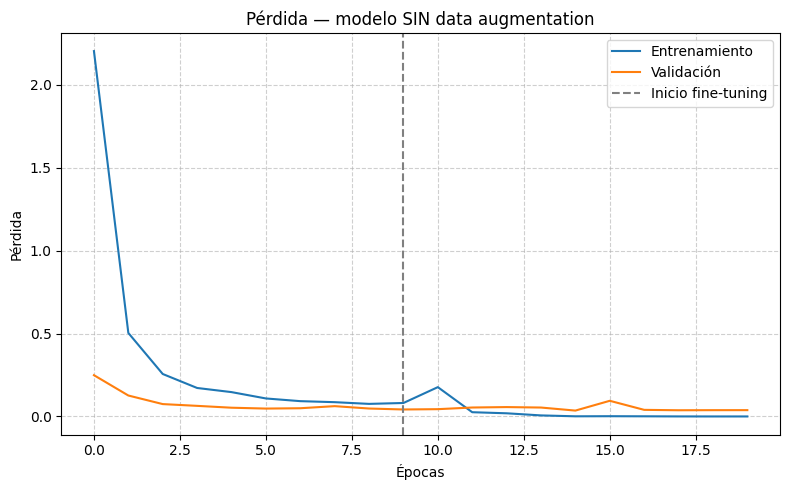

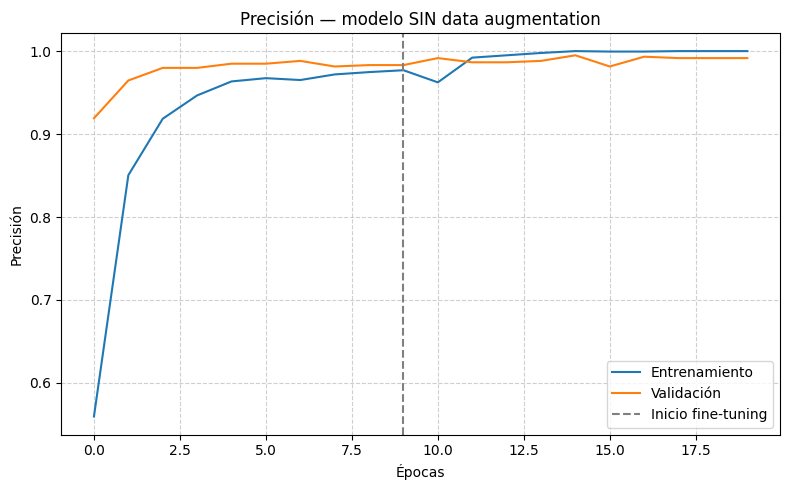

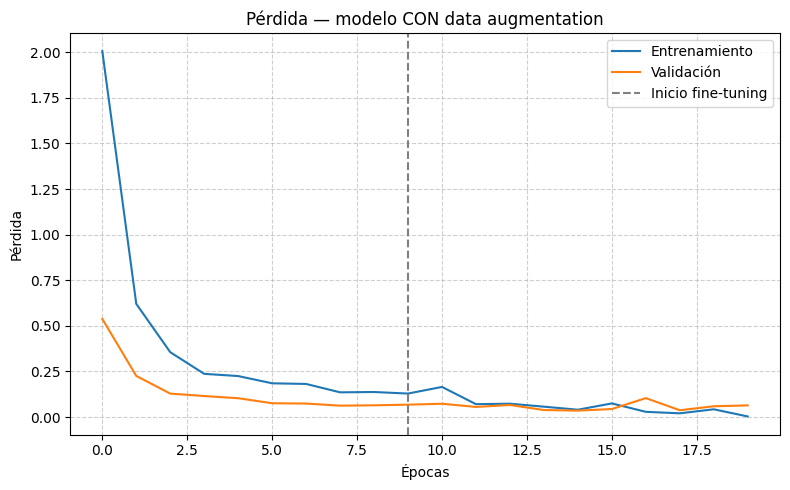

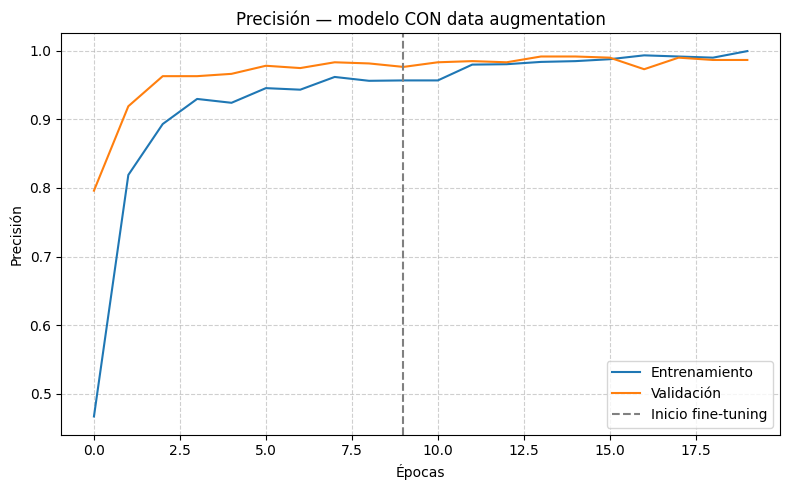

In [74]:
# Historiales completos: extracción de características + fine-tuning
acc_sin = history_sin.history['accuracy'] + history_fine_sin.history['accuracy']
val_acc_sin = history_sin.history['val_accuracy'] + history_fine_sin.history['val_accuracy']
loss_sin = history_sin.history['loss'] + history_fine_sin.history['loss']
val_loss_sin = history_sin.history['val_loss'] + history_fine_sin.history['val_loss']

acc_con = history_con.history['accuracy'] + history_fine_con.history['accuracy']
val_acc_con = history_con.history['val_accuracy'] + history_fine_con.history['val_accuracy']
loss_con = history_con.history['loss'] + history_fine_con.history['loss']
val_loss_con = history_con.history['val_loss'] + history_fine_con.history['val_loss']


def graficar_entrenamiento(train_vals, val_vals, metrica, titulo, archivo, corte_ft):
    plt.figure(figsize=(8, 5))
    plt.plot(train_vals, label='Entrenamiento')
    plt.plot(val_vals, label='Validación')
    plt.axvline(corte_ft - 1, color='gray', linestyle='--', label='Inicio fine-tuning')
    plt.title(titulo)
    plt.xlabel('Épocas')
    plt.ylabel('Precisión' if metrica == 'accuracy' else 'Pérdida')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()


# Modelo SIN data augmentation
graficar_entrenamiento(loss_sin, val_loss_sin, 'loss',
                       'Pérdida — modelo SIN data augmentation',
                       'loss_sin_aug.png', ep_sin)
graficar_entrenamiento(acc_sin, val_acc_sin, 'accuracy',
                       'Precisión — modelo SIN data augmentation',
                       'accuracy_sin_aug.png', ep_sin)

# Modelo CON data augmentation
graficar_entrenamiento(loss_con, val_loss_con, 'loss',
                       'Pérdida — modelo CON data augmentation',
                       'loss_con_aug.png', ep_con)
graficar_entrenamiento(acc_con, val_acc_con, 'accuracy',
                       'Precisión — modelo CON data augmentation',
                       'accuracy_con_aug.png', ep_con)

### Matrices de confusión y reportes

Se evalúa sobre el **conjunto de prueba**, que el modelo nunca vio ni para entrenar ni para *early stopping*: es la estimación más honesta del desempeño.


=== Reporte de clasificación — modelo SIN data augmentation ===
                 precision    recall  f1-score   support

    Cerithiidae      0.993     0.993     0.993       137
Embrionic_shell      1.000     0.989     0.995        93
      Eulimidae      0.975     1.000     0.987        78
     Litiopidae      1.000     1.000     1.000       113
      Neritidae      0.993     1.000     0.996       141
    Risooinidae      1.000     0.935     0.967        31

       accuracy                          0.993       593
      macro avg      0.993     0.986     0.990       593
   weighted avg      0.993     0.993     0.993       593



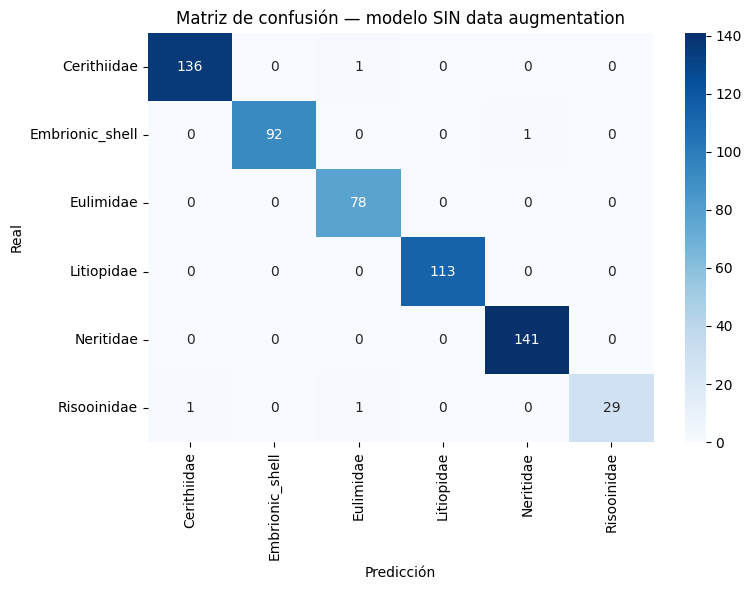


=== Reporte de clasificación — modelo CON data augmentation ===
                 precision    recall  f1-score   support

    Cerithiidae      0.993     0.993     0.993       137
Embrionic_shell      0.989     0.989     0.989        93
      Eulimidae      0.987     1.000     0.994        78
     Litiopidae      1.000     1.000     1.000       113
      Neritidae      0.993     0.993     0.993       141
    Risooinidae      1.000     0.968     0.984        31

       accuracy                          0.993       593
      macro avg      0.994     0.990     0.992       593
   weighted avg      0.993     0.993     0.993       593



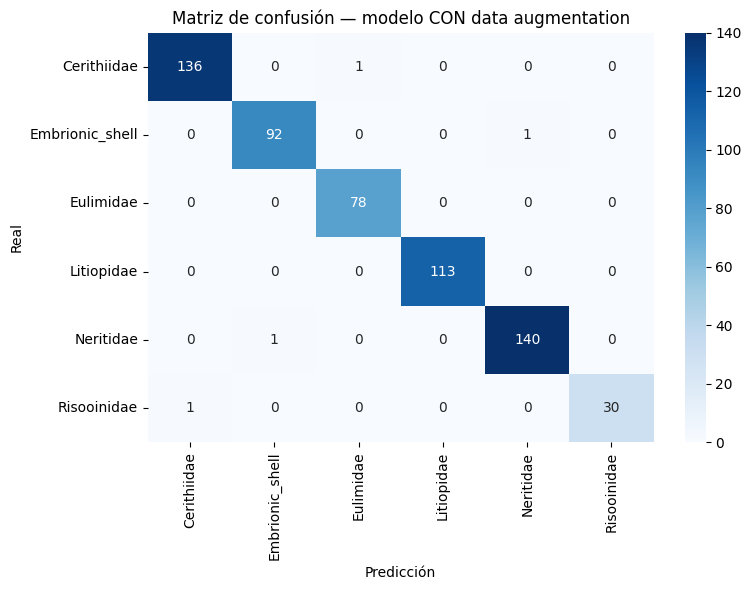

In [75]:
def evaluar_modelo(model, nombre, archivo):
    y_true, y_pred = [], []
    for images, labels in test_dataset:
        logits = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(logits, axis=1))

    print(f"\n=== Reporte de clasificación — modelo {nombre} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicción')
    plt.ylabel('Real')
    plt.title(f'Matriz de confusión — modelo {nombre}')
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()


evaluar_modelo(model_sin_aug, 'SIN data augmentation', 'matriz_sin_aug.png')
evaluar_modelo(model_con_aug, 'CON data augmentation', 'matriz_con_aug.png')

### Comparación conjunta (ambos modelos en la misma gráfica)

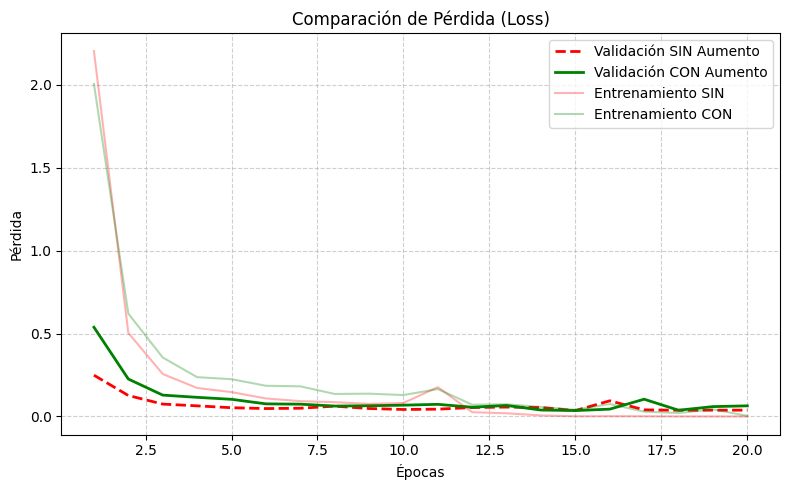

In [76]:
epocas_sin = range(1, len(loss_sin) + 1)
epocas_con = range(1, len(loss_con) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epocas_sin, val_loss_sin, 'r--', linewidth=2, label='Validación SIN Aumento')
plt.plot(epocas_con, val_loss_con, 'g-', linewidth=2, label='Validación CON Aumento')
plt.plot(epocas_sin, loss_sin, 'r', alpha=0.3, label='Entrenamiento SIN')
plt.plot(epocas_con, loss_con, 'g', alpha=0.3, label='Entrenamiento CON')
plt.title('Comparación de Pérdida (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('comparacion_loss.png', dpi=150)
plt.show()

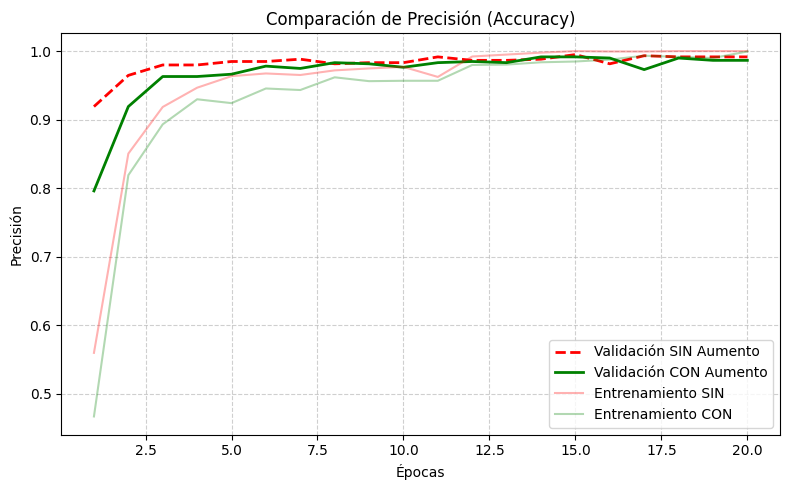

In [77]:
plt.figure(figsize=(8, 5))
plt.plot(epocas_sin, val_acc_sin, 'r--', linewidth=2, label='Validación SIN Aumento')
plt.plot(epocas_con, val_acc_con, 'g-', linewidth=2, label='Validación CON Aumento')
plt.plot(epocas_sin, acc_sin, 'r', alpha=0.3, label='Entrenamiento SIN')
plt.plot(epocas_con, acc_con, 'g', alpha=0.3, label='Entrenamiento CON')
plt.title('Comparación de Precisión (Accuracy)')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('comparacion_accuracy.png', dpi=150)
plt.show()

### Ejemplos de predicción (modelo CON data augmentation)

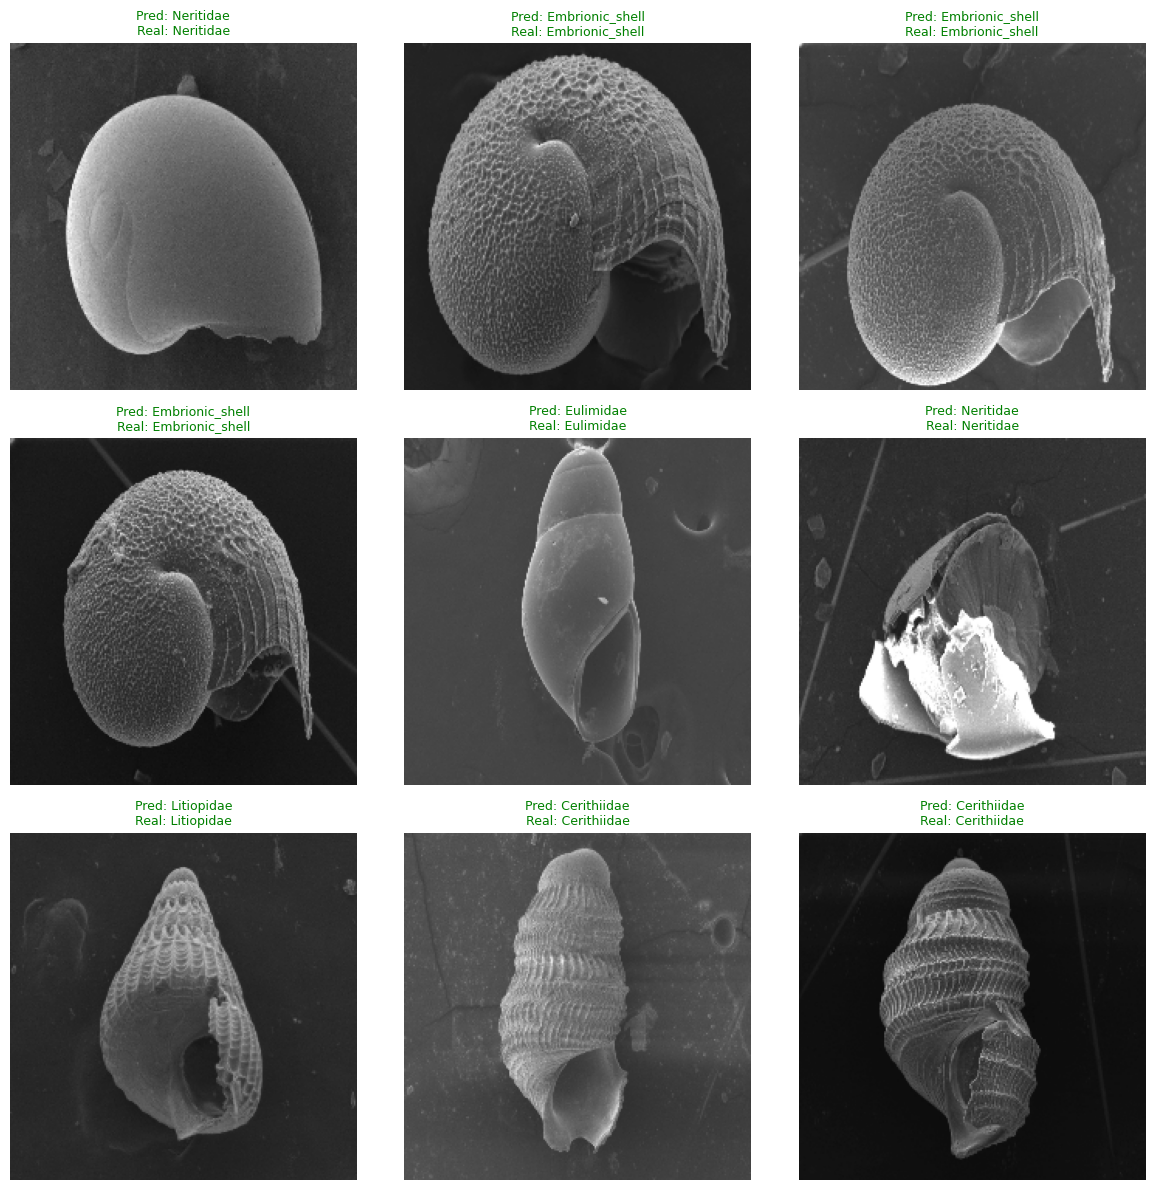

In [78]:
plt.figure(figsize=(12, 12))
for images, labels in test_dataset.take(1):
    preds = np.argmax(model_con_aug.predict(images, verbose=0), axis=1)
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred, real = int(preds[i]), int(labels[i])
        color = 'green' if pred == real else 'red'
        plt.title(f"Pred: {class_names[pred]}\nReal: {class_names[real]}", color=color, fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.savefig('predicciones_ejemplo.png', dpi=150)
plt.show()

In [79]:
model_con_aug.save('clasificador_caracoles.keras')
print("Modelo guardado: clasificador_caracoles.keras")

if os.path.isdir('/content/drive/MyDrive'):
    shutil.copy('clasificador_caracoles.keras', '/content/drive/MyDrive/clasificador_caracoles.keras')
    print("Copia guardada en Drive: /content/drive/MyDrive/clasificador_caracoles.keras")


Modelo guardado: clasificador_caracoles.keras
Copia guardada en Drive: /content/drive/MyDrive/clasificador_caracoles.keras
